# 🔬 Notebook 02: Unsupervised Learning (K-Means & DBSCAN)
## *PRML Laboratory Investigation: Cluster Discovery in 561-D Latent Space*

---
### 🎯 Objectives
1. **K-Means Clustering**: Determine optimal cluster count $k$ using **Inertia (Elbow Method)** and **Silhouette Coefficients**.
2. **DBSCAN Clustering**: Calibrate density parameters (`eps`, `min_samples`) using $k$-NN distance graphs to isolate core density clusters and sensor noise.
3. **Intrinsic Cluster Validation**: Assess cluster quality with **Adjusted Rand Index (ARI)** and **Normalized Mutual Information (NMI)** against ground-truth activity classes.
4. **2D PCA Latent Projection**: Visually inspect clustering boundaries in low-dimensional space.

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
os.makedirs('../models', exist_ok=True)
os.makedirs('../presentation', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

# Load processed dataset from Notebook 01
X_train, y_train, X_test, y_test = joblib.load('../data/processed_data.pkl')
print(f"✅ Data Ingested: X_train shape = {X_train.shape}, Unique Classes = {y_train.nunique()}")

# Standardization of 561 features for isotropic distance metric
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
print("✅ Feature Space Standardized to zero mean and unit variance.")

✅ Data Ingested: X_train shape = (7352, 562), Unique Classes = 6
✅ Feature Space Standardized to zero mean and unit variance.


## 1️⃣ K-Means Clustering: Optimal $k$ Search (Elbow & Silhouette)

Scanning k in range [2, 10]...
  • k =  2 | Inertia = 2343544.95 | Silhouette = 0.3954
  • k =  3 | Inertia = 2089116.85 | Silhouette = 0.3275
  • k =  4 | Inertia = 1983729.49 | Silhouette = 0.1612
  • k =  5 | Inertia = 1882311.74 | Silhouette = 0.1303
  • k =  6 | Inertia = 1826030.57 | Silhouette = 0.1067
  • k =  7 | Inertia = 1783246.73 | Silhouette = 0.1047
  • k =  8 | Inertia = 1742882.42 | Silhouette = 0.0816
  • k =  9 | Inertia = 1703499.47 | Silhouette = 0.0776
  • k = 10 | Inertia = 1666107.37 | Silhouette = 0.0813


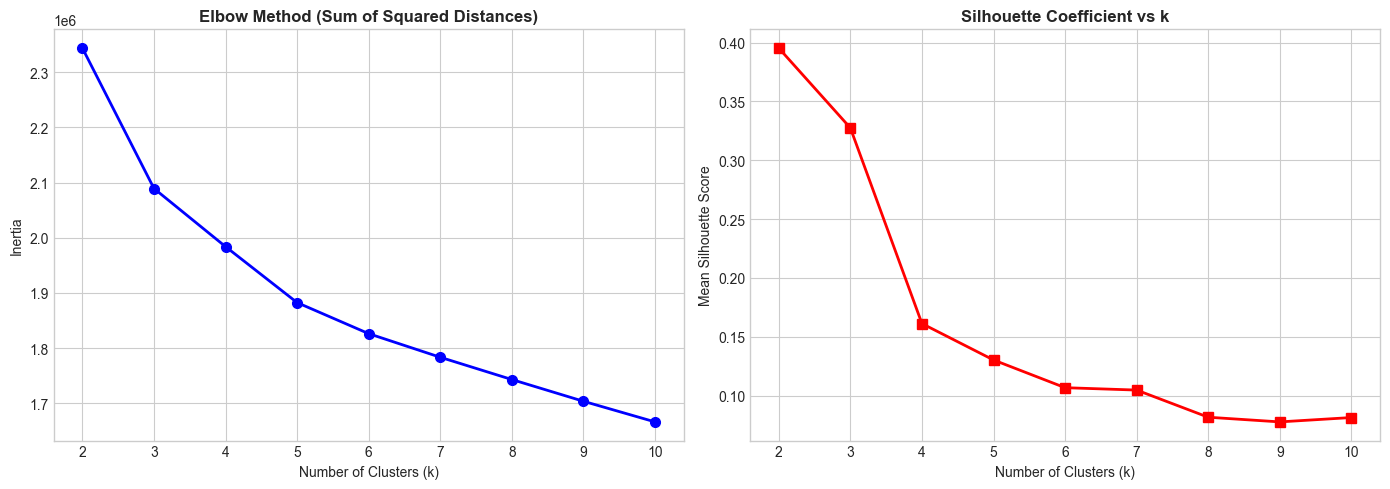

In [2]:
k_range = range(2, 11)
inertias = []
silhouettes = []

print("Scanning k in range [2, 10]...")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_scaled, labels, sample_size=3000, random_state=42)
    silhouettes.append(sil)
    print(f"  • k = {k:2d} | Inertia = {km.inertia_:10.2f} | Silhouette = {sil:.4f}")

# Dual diagnostic plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=7)
axes[0].set_title('Elbow Method (Sum of Squared Distances)', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True)

axes[1].plot(k_range, silhouettes, 'rs-', linewidth=2, markersize=7)
axes[1].set_title('Silhouette Coefficient vs k', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Mean Silhouette Score')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('../presentation/06_kmeans_elbow_silhouette.png', dpi=200)
plt.show()

## 2️⃣ Ground-Truth Alignment with Optimal $k=6$

In [3]:
# Fitting k=6 (matching the 6 ground-truth physical activity categories)
optimal_k = 6
kmeans_opt = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans_opt.fit_predict(X_scaled)

ari = adjusted_rand_score(y_train, kmeans_labels)
nmi = normalized_mutual_info_score(y_train, kmeans_labels)
print("=" * 50)
print(f"K-MEANS VALIDATION AGAINST 6 TRUE ACTIVITIES")
print("=" * 50)
print(f"Adjusted Rand Index (ARI)       : {ari:.4f}")
print(f"Normalized Mutual Info (NMI)   : {nmi:.4f}")

K-MEANS VALIDATION AGAINST 6 TRUE ACTIVITIES
Adjusted Rand Index (ARI)       : 0.4197
Normalized Mutual Info (NMI)   : 0.5589


## 3️⃣ DBSCAN: Density Parameter Tuning with $k$-NN Distance Graph

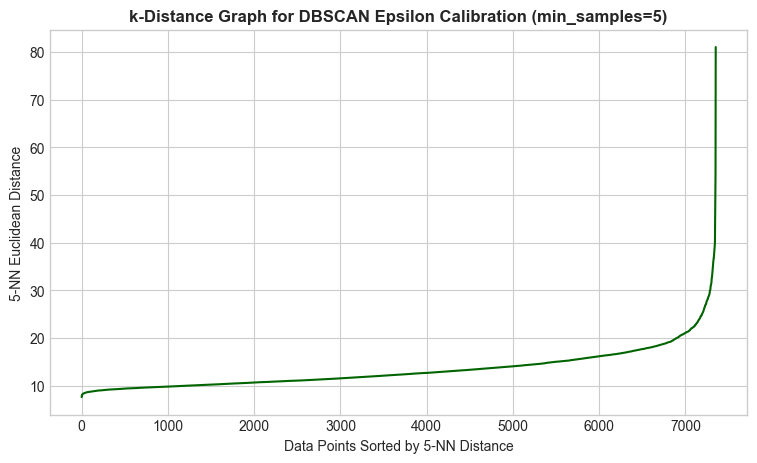

In [4]:
# Estimate eps using knee point in 5-NN distance curve
neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
sorted_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(sorted_distances, color='darkgreen', linewidth=1.5)
plt.title('k-Distance Graph for DBSCAN Epsilon Calibration (min_samples=5)', fontweight='bold')
plt.xlabel('Data Points Sorted by 5-NN Distance')
plt.ylabel('5-NN Euclidean Distance')
plt.grid(True)
plt.savefig('../presentation/07_dbscan_kdistance.png', dpi=200)
plt.show()

In [5]:
# Fit DBSCAN using robust parameters
dbscan = DBSCAN(eps=15.0, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters_ = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_ = list(dbscan_labels).count(-1)
print(f"DBSCAN Estimated Clusters : {n_clusters_}")
print(f"DBSCAN Noise Outliers     : {n_noise_} ({n_noise_ / len(X_scaled) * 100:.2f}%)")

DBSCAN Estimated Clusters : 16
DBSCAN Noise Outliers     : 1393 (18.95%)


## 4️⃣ Cluster Latent Projections (Ground Truth vs K-Means vs DBSCAN)

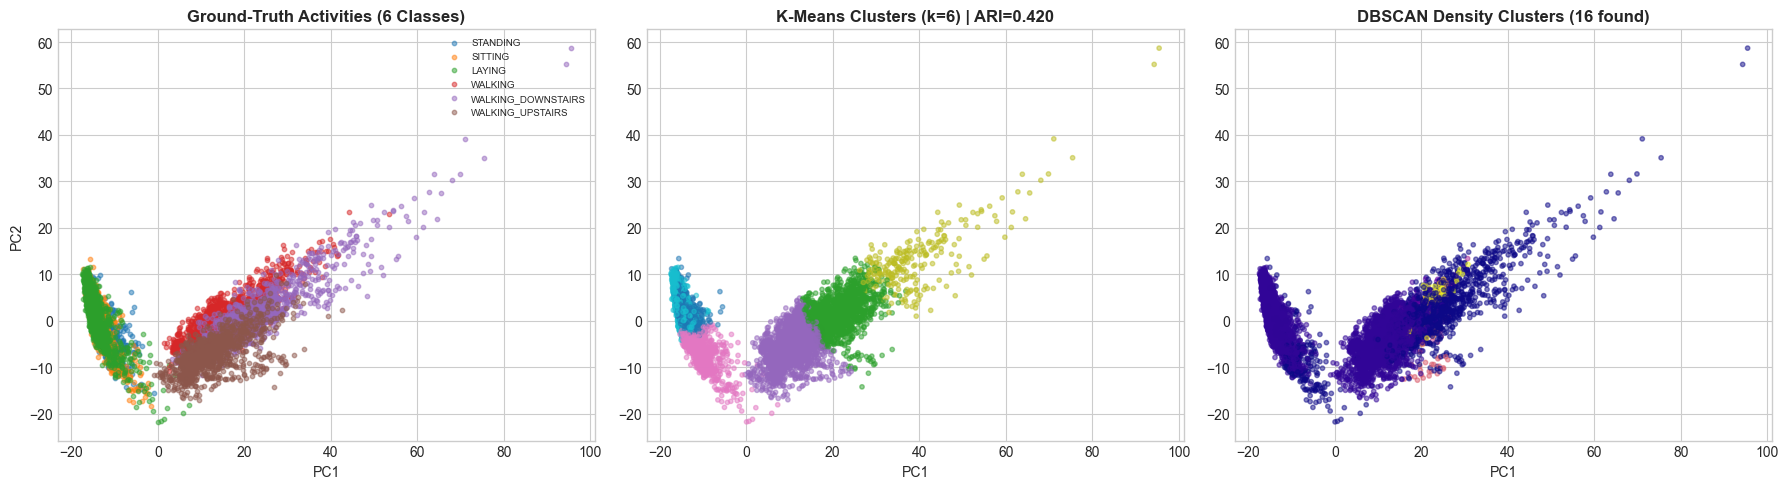

✅ Clustering artifacts serialized to ../models/clustering_results.pkl


In [6]:
# 2D PCA Latent Projection
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. True Activities
for act in y_train.unique():
    mask = (y_train == act)
    axes[0].scatter(X_2d[mask, 0], X_2d[mask, 1], label=act, s=10, alpha=0.5)
axes[0].set_title('Ground-Truth Activities (6 Classes)', fontweight='bold')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(fontsize=7, loc='upper right')

# 2. K-Means Clusters
scatter = axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans_labels, cmap='tab10', s=10, alpha=0.5)
axes[1].set_title(f'K-Means Clusters (k=6) | ARI={ari:.3f}', fontweight='bold')
axes[1].set_xlabel('PC1')

# 3. DBSCAN Clusters
scatter = axes[2].scatter(X_2d[:, 0], X_2d[:, 1], c=dbscan_labels, cmap='plasma', s=10, alpha=0.5)
axes[2].set_title(f'DBSCAN Density Clusters ({n_clusters_} found)', fontweight='bold')
axes[2].set_xlabel('PC1')

plt.tight_layout()
plt.savefig('../presentation/08_clustering_comparison.png', dpi=200)
plt.show()

# Persist clustering results
joblib.dump((kmeans_labels, dbscan_labels, scaler), '../models/clustering_results.pkl')
print('✅ Clustering artifacts serialized to ../models/clustering_results.pkl')